# QL18 corridor on hexagons

Communes are too coarse and too uneven for a corridor a few hundred metres deep: a
roadside ribbon is averaged with kilometres of rice field behind it. Here the
corridor is tiled with **H3 hexagons** instead, at three sizes, and the same ESDA is
run on them:

| H3 resolution | cell area | 10 m pixels per cell |
|---|---|---|
| 8 | ~0.74 km² | ~7,400 |
| 9 | ~0.105 km² | ~1,050 |
| 10 | ~0.015 km² | ~150 |

Resolution 9 is the main scale; 8 and 10 show how much the answer depends on cell
size (MAUP). Hexagons: every neighbour is equidistant and there are always six, so
Queen and Rook contiguity coincide.

**Nothing is masked yet.** Two things will therefore show up, and are worth looking
for in the maps rather than being surprised by later:
- the QL18 carriageway itself is likely classed *Built area*, so every hex it
  crosses gets a few % built-up from pavement alone;
- urban wards (Bắc Ninh, Hạ Long, Móng Cái) are compact cores, which LISA will
  flag as High-High just as it did on communes.

In [1]:
import time
from typing import Final

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from desakota.crs import CRS_UTM
from desakota.hexgrid import build_hex_grid
from desakota.landcover import (
    compute_built_frac_for_tessellation,
    fetch_landcover,
    get_landcover_legend,
)
from desakota.paths import DataLayout
from desakota.stac import create_client, get_bbox_from_aoi, get_collection, search_items

RESOLUTIONS: Final = (8, 9, 10)
MAIN_RESOLUTION: Final = 9
CORRIDOR_BUFFER_M: Final = 2_000  # must match 01
TIME_RANGE: Final = '2023-01-02/2023-12-31'
BUILT_AREA_LABEL: Final = 'Built area'
WATER_LABEL: Final = 'Water'

layout = DataLayout.from_env().ensure()
communes = gpd.read_file(layout.processed / 'communes_ql18_corridor.gpkg')  # EPSG:32648, from 01
route_ways = gpd.read_file(layout.processed / 'highways_ql18.gpkg')  # EPSG:32648, from 01
assert communes.crs == route_ways.crs == CRS_UTM
len(communes), len(route_ways)

(171, 809)

## 1. Footprint

The hexagons cover the 2 km corridor itself, not the whole communes: the band
within `CORRIDOR_BUFFER_M` of the old road, clipped to land (the corridor
communes), so Hạ Long Bay and China are excluded.

footprint: 1071 km2


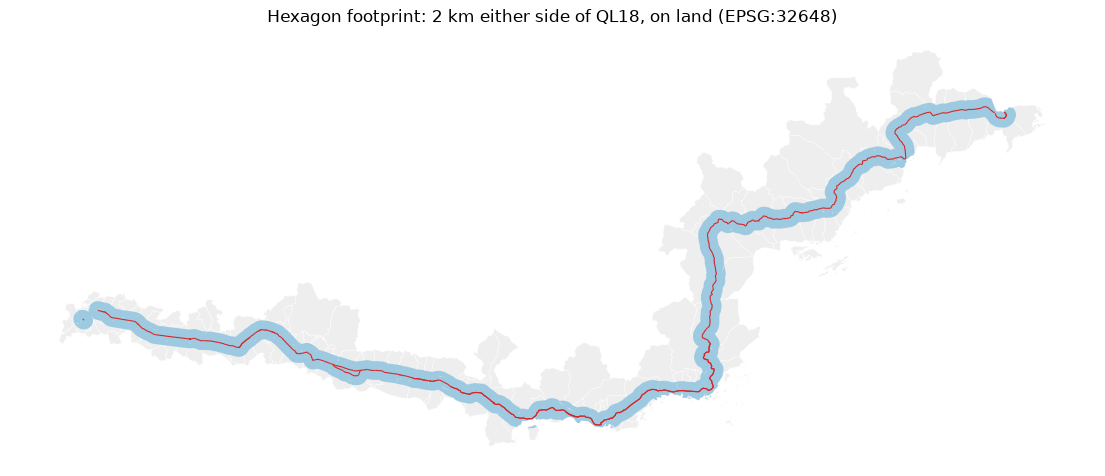

In [2]:
route_line = route_ways.union_all()
footprint = route_line.buffer(CORRIDOR_BUFFER_M).intersection(communes.union_all())

ax = communes.plot(color='#eeeeee', edgecolor='white', linewidth=0.3, figsize=(14, 6))
gpd.GeoSeries([footprint], crs=CRS_UTM).plot(ax=ax, color='#9ecae1')
route_ways.plot(ax=ax, color='#d62728', linewidth=0.8)
ax.set_title('Hexagon footprint: 2 km either side of QL18, on land (EPSG:32648)')
ax.set_axis_off()
print(f'footprint: {footprint.area / 1e6:.0f} km2')

## 2. Hexagon grids

`build_hex_grid` selects H3 cells whose centre falls in the footprint grown by one
hexagon edge, then clips them to the footprint, so the cells partition it exactly.
Edge cells are partial hexagons.

In [3]:
hex_grids = {res: build_hex_grid(footprint, crs=CRS_UTM, resolution=res) for res in RESOLUTIONS}

pd.DataFrame(
    [
        {
            'resolution': res,
            'n_hexes': len(grid),
            'median_area_km2': round(grid.area.median() / 1e6, 4),
            # whole interior cells only, to see H3's own size variation in UTM
            'area_spread_frac': round(
                (lambda whole: (whole.max() - whole.min()) / whole.median())(
                    grid.area[grid.area > 0.99 * grid.area.median()]
                ),
                4,
            ),
            'total_km2': round(grid.area.sum() / 1e6),
        }
        for res, grid in hex_grids.items()
    ]
)

,resolution,n_hexes,median_area_km2,area_spread_frac,total_km2
0,8,1725,0.7872,0.0286,1071
1,9,10485,0.1132,0.0216,1071
2,10,68861,0.0162,0.0198,1071


How the three sizes compare to the road: a zoom on a few km of QL18 around Phả
Lại / Chí Linh.

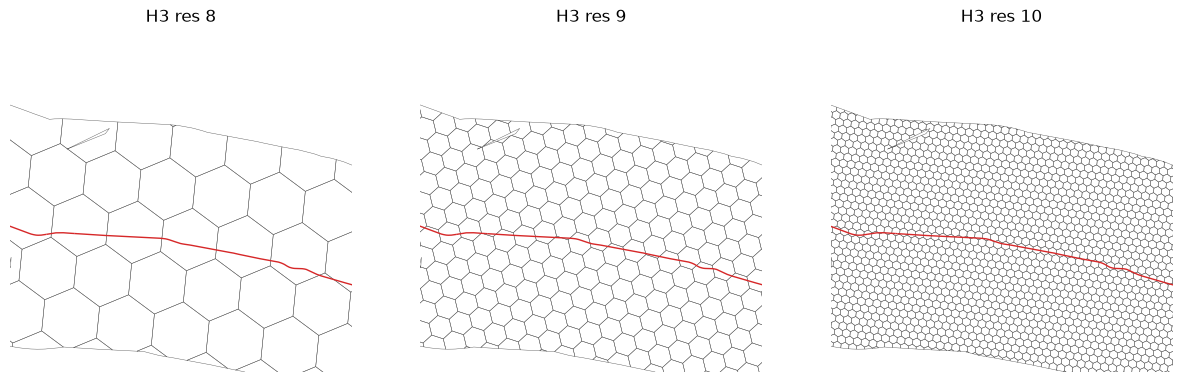

In [4]:
zoom = communes[communes['district_name'] == 'ChíLinh'].total_bounds
zoom_xlim, zoom_ylim = (zoom[0], zoom[0] + 6_000), (zoom[1] + 3_000, zoom[1] + 9_000)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (res, grid) in zip(axes, hex_grids.items(), strict=True):
    grid.boundary.plot(ax=ax, color='#555555', linewidth=0.3)
    route_ways.plot(ax=ax, color='#d62728', linewidth=1)
    ax.set_xlim(zoom_xlim)
    ax.set_ylim(zoom_ylim)
    ax.set_title(f'H3 res {res}')
    ax.set_axis_off()

## 3. Built-up share per hexagon

Same land cover as 01 (io-lulc 2023, tile 48Q; the cached clip is reused). Each 10 m
pixel goes to the hexagon containing its centre, so no pixel is counted twice; water
is left out of the denominator, and a hex with no land pixel gets NaN.

In [5]:
client = create_client()
collection = get_collection(client, '10M_ANNUAL_LANDUSE')
legend = get_landcover_legend(collection)
items = search_items(
    client, collection, bbox=get_bbox_from_aoi(communes.to_crs('EPSG:4326')), datetime=TIME_RANGE
).items()
lulc_item = next(item for item in items if item.id.startswith('48Q'))
lulc_path = fetch_landcover(communes, lulc_item, cache_dir=layout.raw / 'lulc')  # cached by 01
lulc_path.name

'lulc_48Q-2023_3d7e0d2660ca.tif'

In [6]:
for res, grid in hex_grids.items():
    started_s = time.perf_counter()
    grid['built_frac'] = compute_built_frac_for_tessellation(
        grid, lulc_path, legend, built_area_label=BUILT_AREA_LABEL, water_label=WATER_LABEL
    )
    grid['dist_to_ql18_m'] = grid.distance(route_line).round(1)
    print(
        f'res {res}: {time.perf_counter() - started_s:.0f} s, '
        f'{grid["built_frac"].isna().sum()} hexes with no land pixel'
    )
hex_grids[MAIN_RESOLUTION]['built_frac'].describe()

res 8: 2 s, 37 hexes with no land pixel


res 9: 3 s, 477 hexes with no land pixel


res 10: 11 s, 5583 hexes with no land pixel


count    10008.000000
mean         0.408579
std          0.404687
min          0.000000
25%          0.000000
50%          0.284396
75%          0.853580
max          1.000000
Name: built_frac, dtype: float64

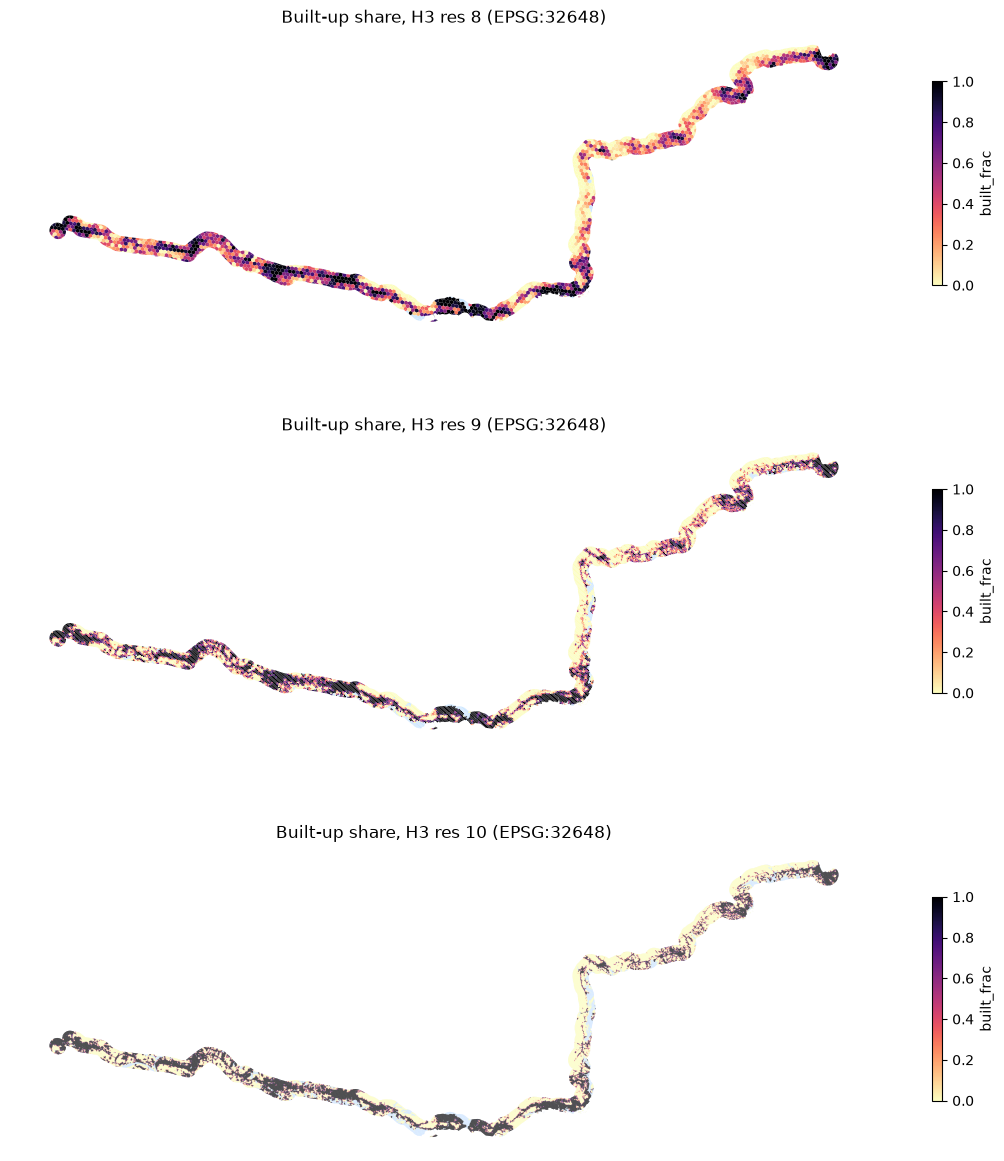

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 15))
for ax, (res, grid) in zip(axes, hex_grids.items(), strict=True):
    grid.plot(
        ax=ax,
        column='built_frac',
        cmap='magma_r',
        vmin=0,
        vmax=1,
        legend=True,
        legend_kwds={'shrink': 0.6, 'label': 'built_frac'},
        missing_kwds={'color': '#cfe8ff'},
    )
    ax.set_title(f'Built-up share, H3 res {res} (EPSG:32648)')
    ax.set_axis_off()

The whole corridor hides the detail. The same zoom as above, where ribbons (or
the pavement signal) should show as a line of darker cells along the road:

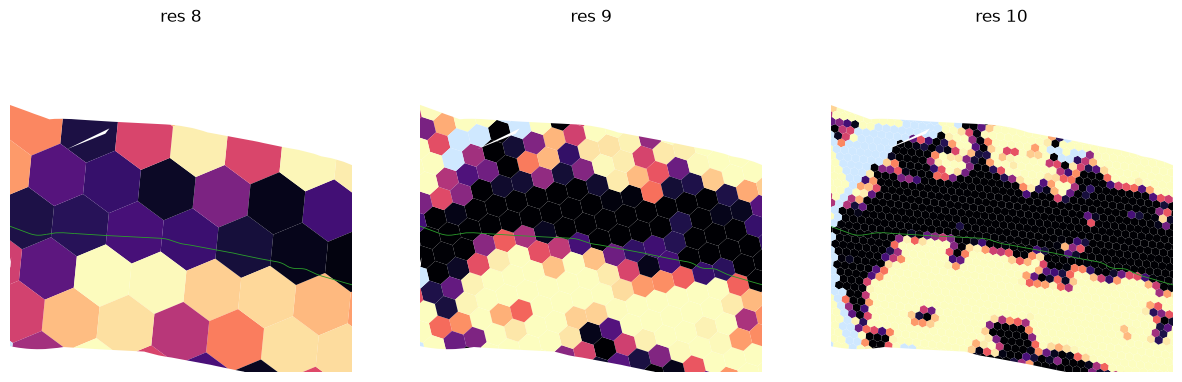

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (res, grid) in zip(axes, hex_grids.items(), strict=True):
    grid.cx[zoom_xlim[0] : zoom_xlim[1], zoom_ylim[0] : zoom_ylim[1]].plot(
        ax=ax,
        column='built_frac',
        cmap='magma_r',
        vmin=0,
        vmax=1,
        missing_kwds={'color': '#cfe8ff'},
    )
    route_ways.plot(ax=ax, color='#2ca02c', linewidth=0.6)
    ax.set_xlim(zoom_xlim)
    ax.set_ylim(zoom_ylim)
    ax.set_title(f'res {res}')
    ax.set_axis_off()

**Distance decay.** If development hugs QL18, built-up share should fall with
distance from the road and flatten into a rural background. The first band also
contains the pavement, so read it with that in mind.

,res 8,res 9,res 10
dist_to_ql18_m,,,
"(-0.001, 100.0]",0.560,0.768,1.000
"(100.0, 250.0]",0.378,0.482,0.687
"(250.0, 500.0]",0.355,0.343,0.362
"(500.0, 1000.0]",0.301,0.245,0.068
"(1000.0, 1500.0]",0.225,0.123,0.000
"(1500.0, 2000.0]",0.094,0.022,0.000


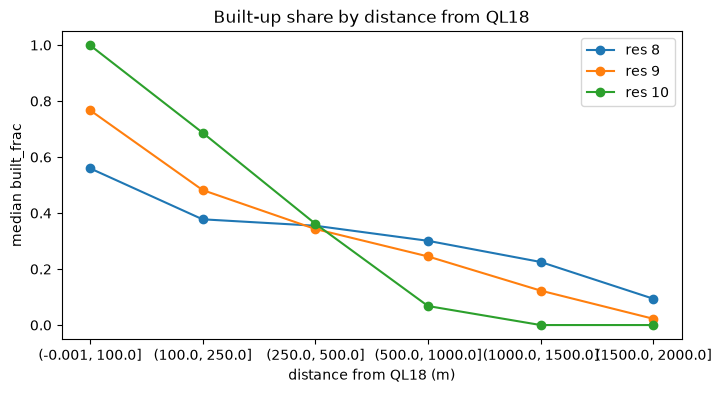

In [9]:
DIST_BANDS_M: Final = [0, 100, 250, 500, 1_000, 1_500, 2_000]

decay = pd.DataFrame(
    {
        f'res {res}': grid.groupby(
            pd.cut(grid['dist_to_ql18_m'], DIST_BANDS_M, include_lowest=True), observed=True
        )['built_frac'].median()
        for res, grid in hex_grids.items()
    }
)
ax = decay.plot(marker='o', figsize=(8, 4))
ax.set_xlabel('distance from QL18 (m)')
ax.set_ylabel('median built_frac')
ax.set_title('Built-up share by distance from QL18')
decay.round(3)

## 4. ESDA at the main resolution

Queen contiguity on hexagons = the six edge neighbours (clipped edge cells may have
fewer). Hexes with no land pixel (NaN) are dropped first. Any cell left without a
neighbour (a coastal sliver) is attached to its nearest one, as in 02.

/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 1444 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/util.py:1343: UserWarning: The weights matrix is not fully connected: 
 There are 9 disconnected components.
  return W(neighbors, weights, id_order=w.id_order, **kwargs)


10008 hexes, mean 5.55 neighbours, 9 component(s)


Moran's I = 0.708, pseudo p = 0.001


/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/spreg/diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


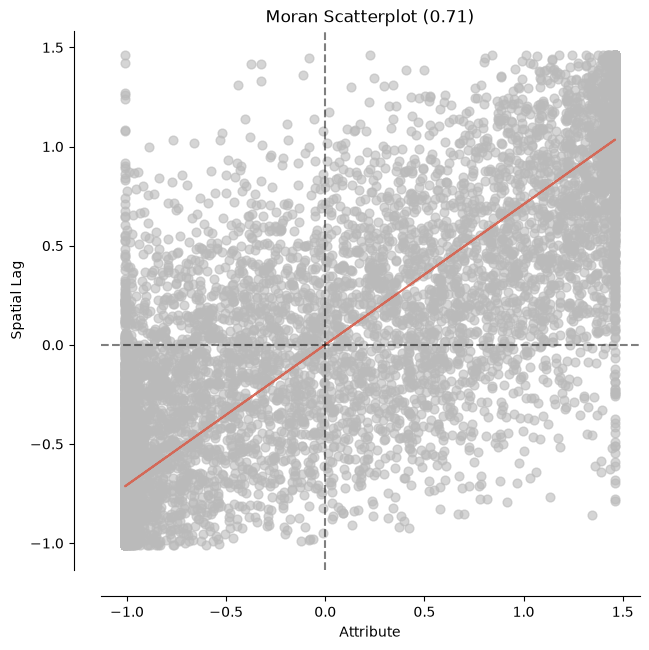

In [10]:
import esda
import libpysal
from splot.esda import lisa_cluster, moran_scatterplot


def build_queen_weights(units: gpd.GeoDataFrame) -> libpysal.weights.W:
    """Queen contiguity, islands attached by KNN-1, row-standardised."""
    w_queen = libpysal.weights.Queen.from_dataframe(units, use_index=False, silence_warnings=True)
    if w_queen.islands:
        w_knn1 = libpysal.weights.KNN.from_dataframe(units, k=1, use_index=False)
        w_queen = libpysal.weights.attach_islands(w_queen, w_knn1)
    w_queen.transform = 'r'
    return w_queen


hexes = hex_grids[MAIN_RESOLUTION].dropna(subset=['built_frac']).reset_index(drop=True)
w_queen = build_queen_weights(hexes)
print(
    f'{w_queen.n} hexes, mean {w_queen.mean_neighbors:.2f} neighbours, {w_queen.n_components} component(s)'
)

moran_built_frac = esda.Moran(hexes['built_frac'], w_queen)
print(f"Moran's I = {moran_built_frac.I:.3f}, pseudo p = {moran_built_frac.p_sim}")
moran_scatterplot(moran_built_frac);

LISA at the usual pseudo p < 0.05 (02 used 0.5, which keeps many non-significant
cells). 999 conditional permutations; with ~10,000 cells some false positives are
expected, so read clusters, not single cells. Single process: parallel workers each copy
the data and run a 7 GB WSL out of memory.

Text(0.5, 1.0, 'LISA clusters of built_frac, H3 res 9, p < 0.05')

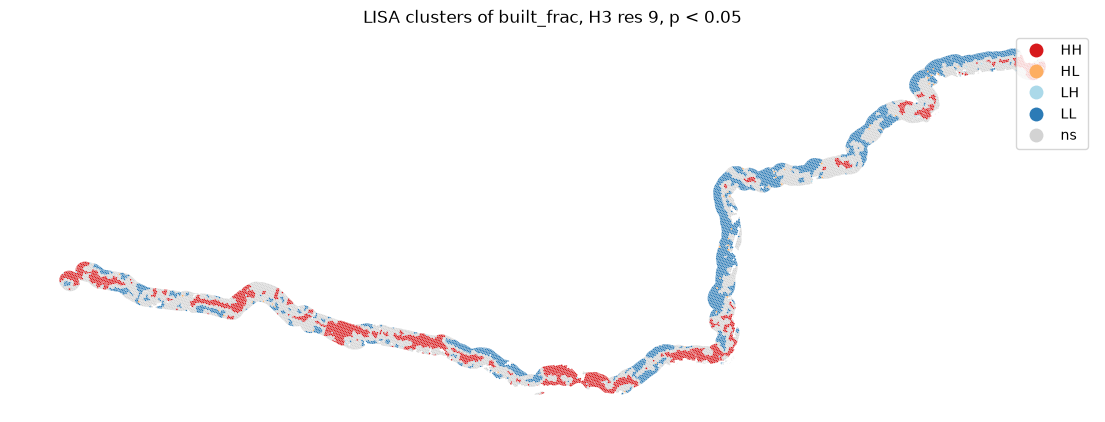

In [11]:
lisa_built_frac = esda.Moran_Local(
    hexes['built_frac'], w_queen, permutations=999, seed=42, n_jobs=1
)  # n_jobs=-1 forks 32 copies: OOM in 7 GB
hexes['lisa_quadrant'] = lisa_built_frac.q
hexes['lisa_p_sim'] = lisa_built_frac.p_sim

fig, ax = lisa_cluster(lisa_built_frac, hexes, p=0.05, figsize=(14, 6))
ax.set_title(f'LISA clusters of built_frac, H3 res {MAIN_RESOLUTION}, p < 0.05')

Text(0.5, 1.0, 'LISA clusters, zoom (black = QL18)')

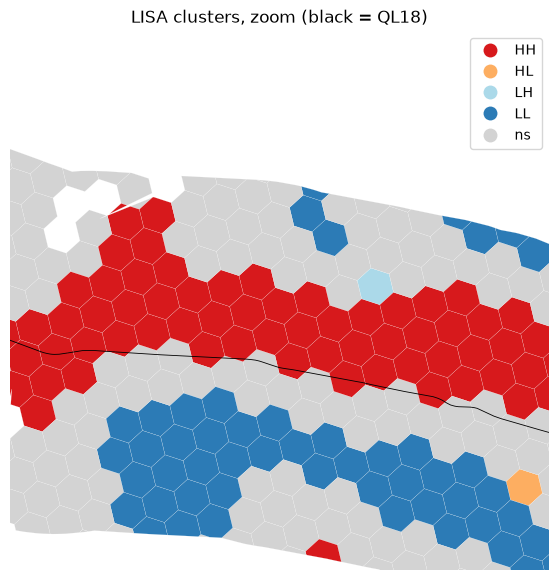

In [12]:
fig, ax = lisa_cluster(lisa_built_frac, hexes, p=0.05, figsize=(7, 7))
route_ways.plot(ax=ax, color='black', linewidth=0.6)
ax.set_xlim(zoom_xlim)
ax.set_ylim(zoom_ylim)
ax.set_title('LISA clusters, zoom (black = QL18)')

**Does it depend on hex size?** Global Moran's I and the share of significant
High-High cells at each resolution. (LISA maps at res 8 and 10 can be drawn the same
way; only the numbers are shown here.)

In [13]:
rows = []
for res, grid in hex_grids.items():
    units = grid.dropna(subset=['built_frac']).reset_index(drop=True)
    w = build_queen_weights(units)
    moran = esda.Moran(units['built_frac'], w, permutations=99)
    local = esda.Moran_Local(units['built_frac'], w, permutations=99, seed=42, n_jobs=1)
    is_hh = (local.q == 1) & (local.p_sim < 0.05)
    rows.append(
        {
            'resolution': res,
            'n_hexes': w.n,
            'moran_I': round(moran.I, 3),
            'hh_frac': round(is_hh.mean(), 3),
            'hh_median_dist_to_ql18_m': round(units.loc[is_hh, 'dist_to_ql18_m'].median()),
        }
    )
pd.DataFrame(rows)

/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 442 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 1444 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/util.py:1343: UserWarning: The weights matrix is not fully connected: 
 There are 9 disconnected components.
  return W(neighbors, weights, id_order=w.id_order, **kwargs)


/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 4482 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/util.py:1343: UserWarning: The weights matrix is not fully connected: 
 There are 46 disconnected components.
  return W(neighbors, weights, id_order=w.id_order, **kwargs)


,resolution,n_hexes,moran_I,hh_frac,hh_median_dist_to_ql18_m
0,8,1688,0.633,0.147,287
1,9,10008,0.708,0.235,468
2,10,63278,0.813,0.252,547


## 5. Save

In [14]:
for res, grid in hex_grids.items():
    stem = f'hexes_built_frac_h3r{res}'
    grid.to_file(layout.processed / f'{stem}.gpkg', layer=stem, driver='GPKG')
stem = f'hexes_lisa_built_frac_h3r{MAIN_RESOLUTION}'
hexes.to_file(layout.processed / f'{stem}.gpkg', layer=stem, driver='GPKG')
sorted(p.name for p in layout.processed.glob('hexes_*.gpkg'))

['hexes_built_frac_h3r10.gpkg',
 'hexes_built_frac_h3r8.gpkg',
 'hexes_built_frac_h3r9.gpkg',
 'hexes_lisa_built_frac_h3r9.gpkg']